<div style="text-align: center;">
  <img width="420" height="420" src="https://raw.githubusercontent.com/eXascaleInfolab/ImputeGAP/main/assets/logo_imputegab.png" />
</div>
<h1>ImputeGAP: Tutorial Notebook</h1>




Notebook 1: Manager

# 1.&nbsp;Installation


ImputeGAP is a comprehensive end-to-end imputation library that covers the whole imputation workflow, from data collection to explaining the results and their implications. It consists of two interconnected components: the imputation module and the advanced analysis module. These components can be used together through a standardized and configuration-based pipeline, or separately via independent instantiation. The documentation is available on: https://imputegap.readthedocs.io/

This notebook showcases key steps of the imputation: imputation pipeline synthesis and advanced analysis. Before getting started, please make sure to install the library along with the required Jupyter dependencies:

In [ ]:
%pip install imputegap==1.1.3

In [ ]:
%pip install -U ipywidgets

In [3]:
import pandas as pd
def imputegap_jupyter(matrix):
    df = pd.DataFrame(matrix).head(10).reset_index(drop=True)
    df.index += 1  # Start index at 1 instead of 0
    return df.style.format(precision=2)

# 2.&nbsp;Dataset Handling

ImputeGAP comes with several time series datasets stored in the module `ts.datasets`. Those datasets contain real-world time series from various of applications and which cover a wide range of characteristics and sizes. All the publicly available datasets provided by the library can be listed using:

In [4]:
from imputegap.recovery.manager import TimeSeries
from imputegap.tools import utils

# initialize the time series object
ts = TimeSeries()

ts.datasets


ImputeGAP Library has been invoked (https://github.com/eXascaleInfolab/ImputeGAP)



['airq',
 'bafu',
 'chlorine',
 'climate',
 'drift',
 'eeg-alcohol',
 'electricity',
 'forecast-economy',
 'meteo',
 'motion',
 'soccer',
 'sport-activity',
 'stock-exchange',
 'temperature',
 'traffic']

## 2.1&nbsp;Dataset Loading

The **EEG-Alcohol** dataset, owned by Henri Begleiter EEG dataset, is utilized in various studies such as Statistical mechanics of neocortical interactions: Canonical momenta indicatorsof electroencephalography. It describes an EEG database composed of individuals with a genetic predisposition to alcoholism. The dataset contains measurements from 64 electrodes placed on subject's scalps which were sampled at 256 Hz (3.9-msec epoch) for 1 second. The dataset contains a total of 416 samples. The specific subset used in ImputeGAP is the S2 match for trial 119, identified as co3a0000458.rd. The dataset's dimensions are 64 series, each containing 256 values. This dataset is primarily used for the analysis of medical and brain-related data, with a focus on detecting predictable patterns in brain wave activity.

<br>


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/eeg-alcohol.txt

> logs: normalization (z_score) of the data - runtime: 0.0009 seconds

plots saved in: ./imputegap_assets/26_11_26_17_05_42_imputegap_plot.jpg


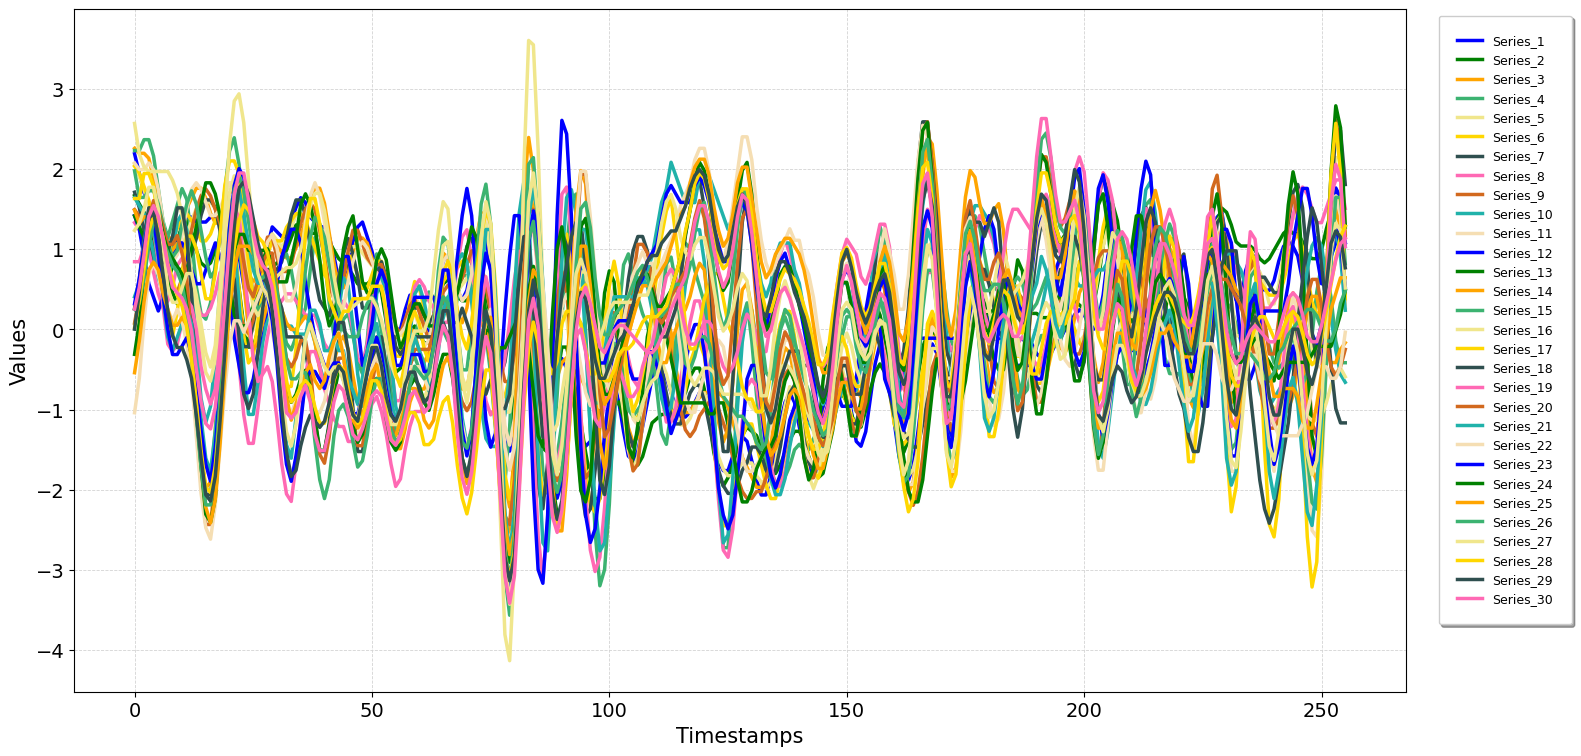

In [6]:
# load the dataset from the library
ts.load_series("eeg-alcohol")
ts.plot(input_data=ts.data, nbr_series=30, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

The **Electricity** dataset has data on household energy consumption of 370 individual clients collected every minute between 2006 and 2010 in France (obtained from the UCI repository).


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/electricity.txt

> logs: normalization (z_score) of the data - runtime: 0.0015 seconds

plots saved in: ./imputegap_assets/26_11_26_17_05_49_imputegap_plot.jpg


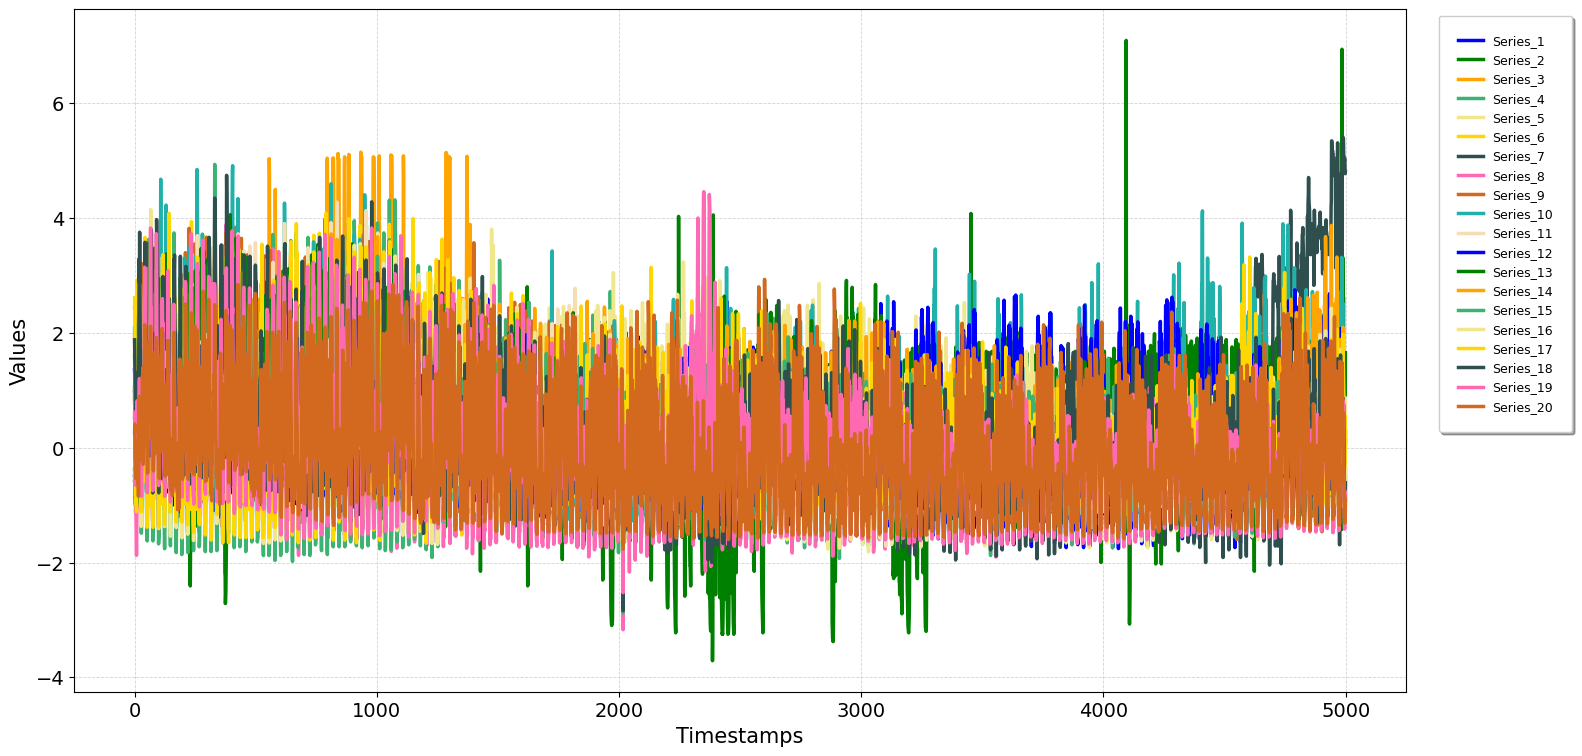

In [7]:
# load the dataset from the library
ts.load_series("electricity")
ts.plot(input_data=ts.data, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

The **Soccer** dataset, initially presented in the DEBS Challenge 2013, captures player positions during a football match. The data is collected from sensors placed near players' shoes and the goalkeeper's hands. With a high tracking frequency of 200Hz, it generates 15,000 position events per second. Soccer time series exhibit bursty behavior and contain numerous outliers.


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/soccer.txt

> logs: normalization (z_score) of the data - runtime: 0.0209 seconds

plots saved in: ./imputegap_assets/26_11_26_17_05_56_imputegap_plot.jpg


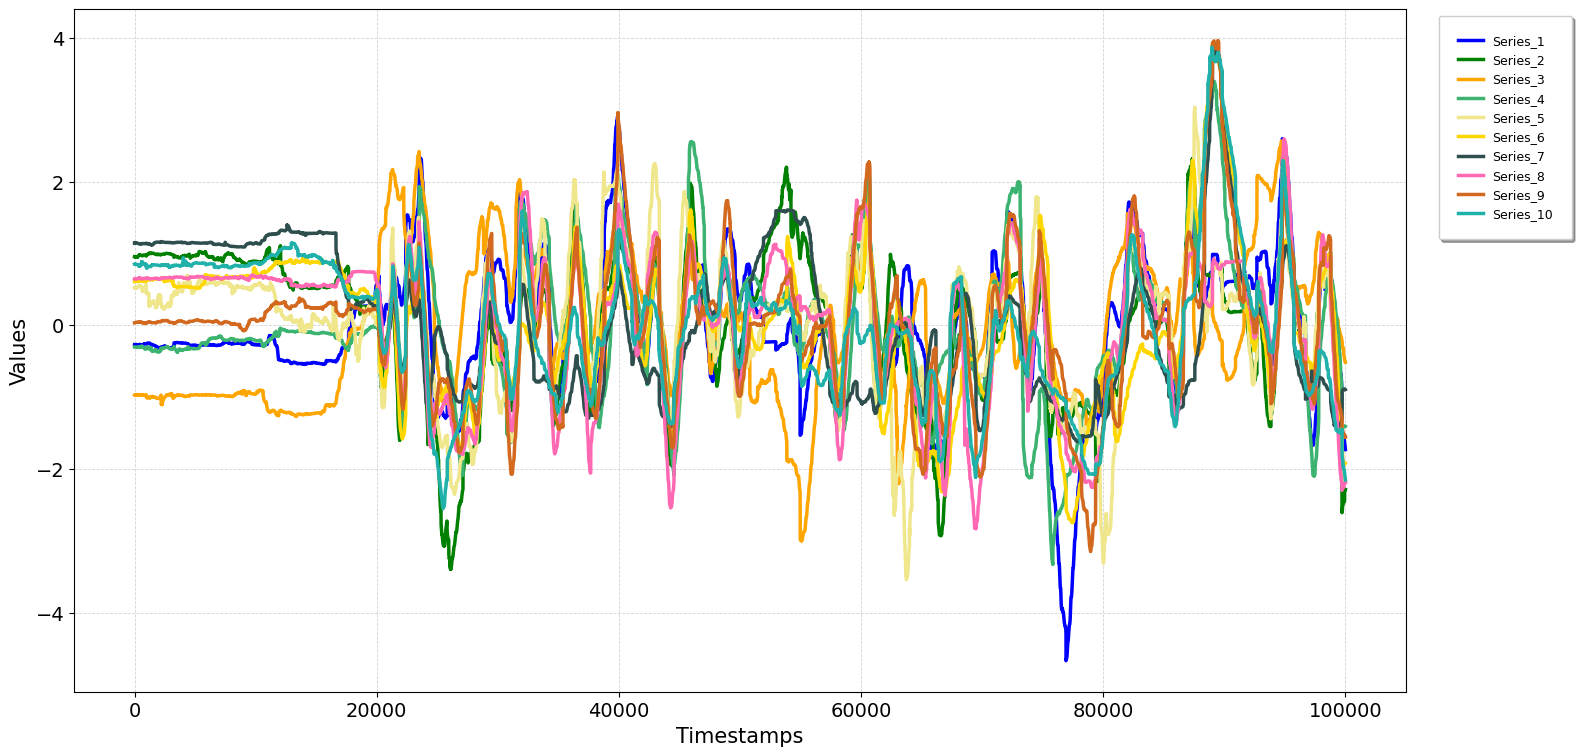

In [8]:
# load the dataset from the library
ts.load_series("soccer")
ts.plot(input_data=ts.data, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

The **Stock-exchange** dataset contains collection of the daily exchange rates of eight foreign countries including Australia, British, Canada, Switzerland, China, Japan, New Zealand and Singapore ranging from 1990 to 2016.


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/stock-exchange.txt

> logs: normalization (z_score) of the data - runtime: 0.0017 seconds

plots saved in: ./imputegap_assets/26_11_26_17_06_03_imputegap_plot.jpg


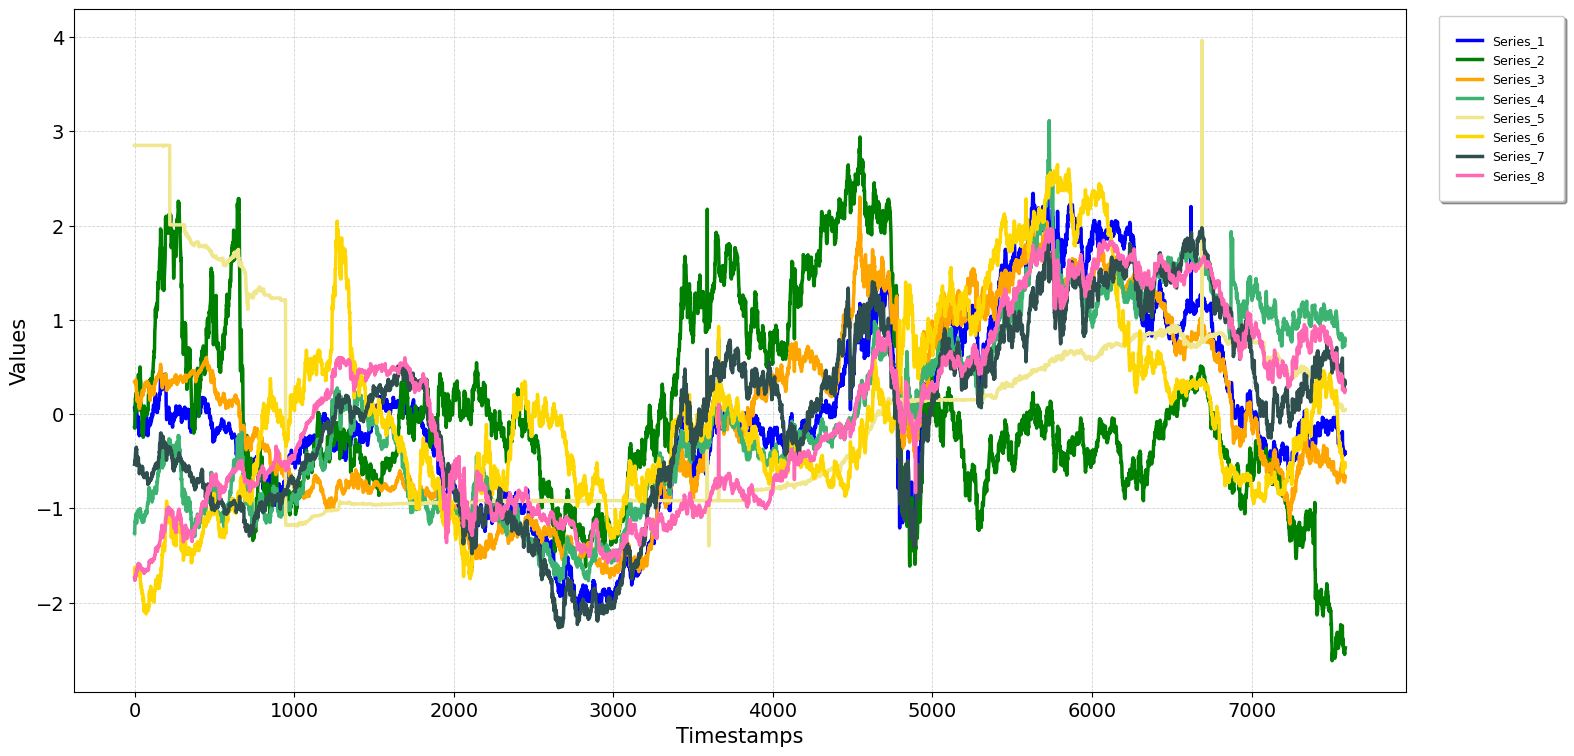

In [9]:
# load the dataset from the library
ts.load_series("stock-exchange")
ts.plot(input_data=ts.data, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

The **Motion** dataset consists of time series data collected from accelerometer and gyroscope sensors, capturing attributes such as attitude, gravity, user acceleration, and rotation rate. Recorded at a high sampling rate of 50Hz using an iPhone 6s placed in users' front pockets, the data reflects various human activities.


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/motion.txt

> logs: normalization (z_score) of the data - runtime: 0.0028 seconds

plots saved in: ./imputegap_assets/26_11_26_17_06_11_imputegap_plot.jpg


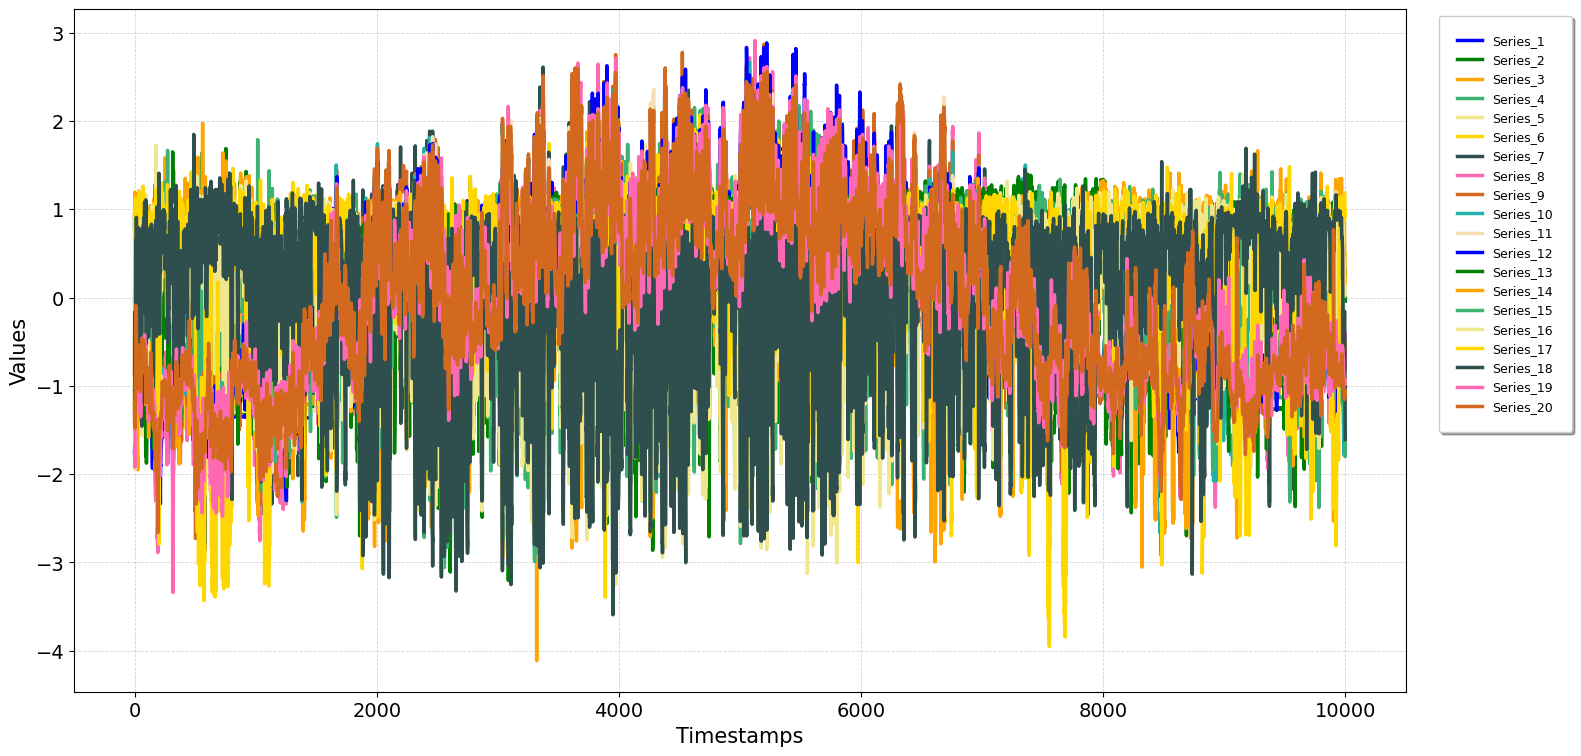

In [10]:
# load the dataset from the library
ts.load_series("motion")
ts.plot(input_data=ts.data, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

The **Climate** dataset is an aggregated and processed collection used for climate change attribution studies. It contains observations data for 18 climate agents across 125 locations in North America USC Melady Lab. The dataset has a temporal granularity of 1 month, comprising 10 series with 5,000 values each. This structure is particularly valuable for spatio-temporal modeling Spatial-temporal causal modeling for climate change attribution, as it enables researchers to account for both spatial and temporal dependencies.


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/climate.txt

> logs: normalization (z_score) of the data - runtime: 0.0012 seconds

plots saved in: ./imputegap_assets/26_11_26_17_06_17_imputegap_plot.jpg


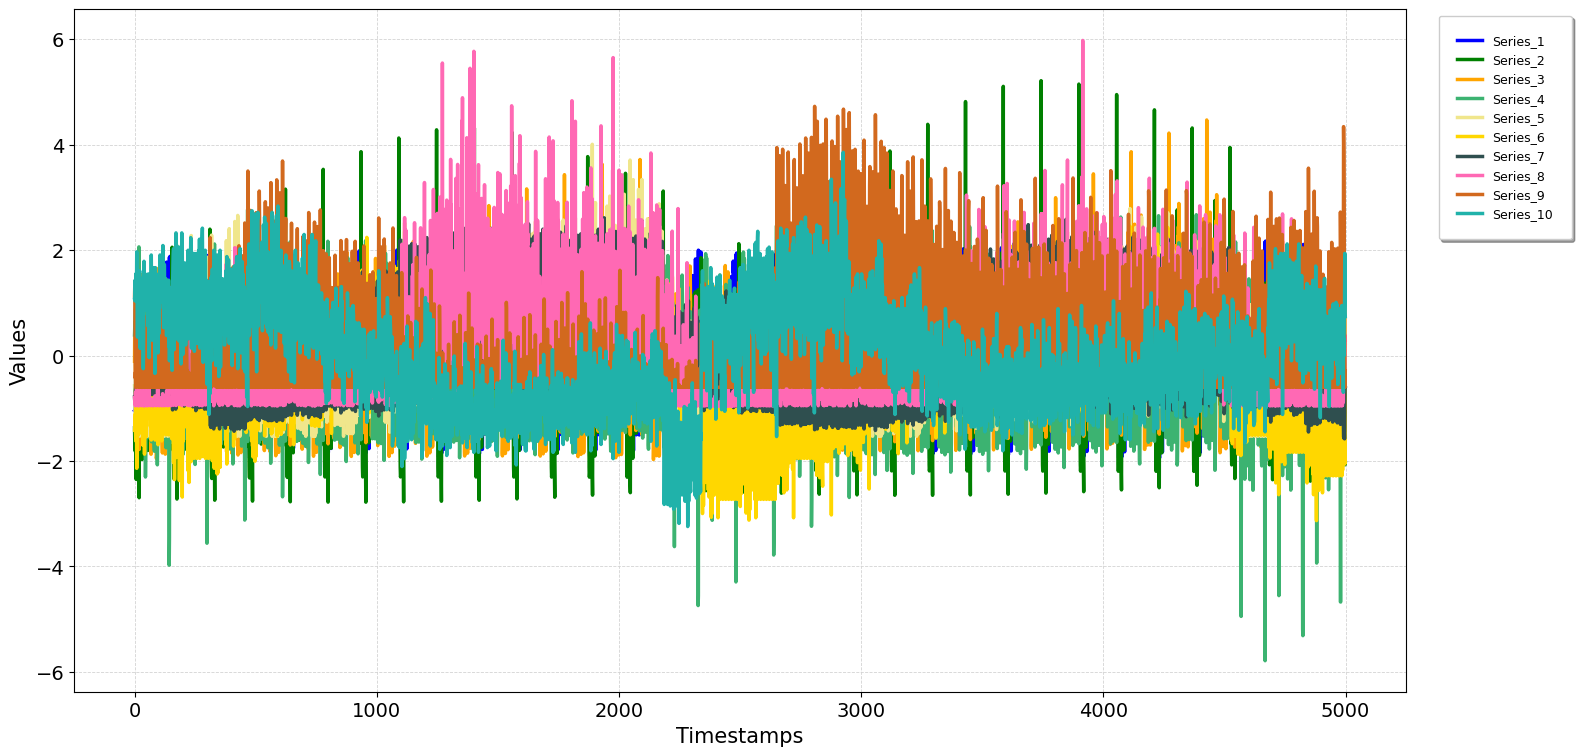

In [11]:
# load the dataset from the library
ts.load_series("climate")
ts.plot(input_data=ts.data, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

The **Air Quality** dataset includes a subset of air quality measurements collected from 36 monitoring stations in China from 2014 to 2015.




(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/airq.txt

> logs: normalization (z_score) of the data - runtime: 0.0007 seconds

plots saved in: ./imputegap_assets/26_11_26_17_06_24_imputegap_plot.jpg


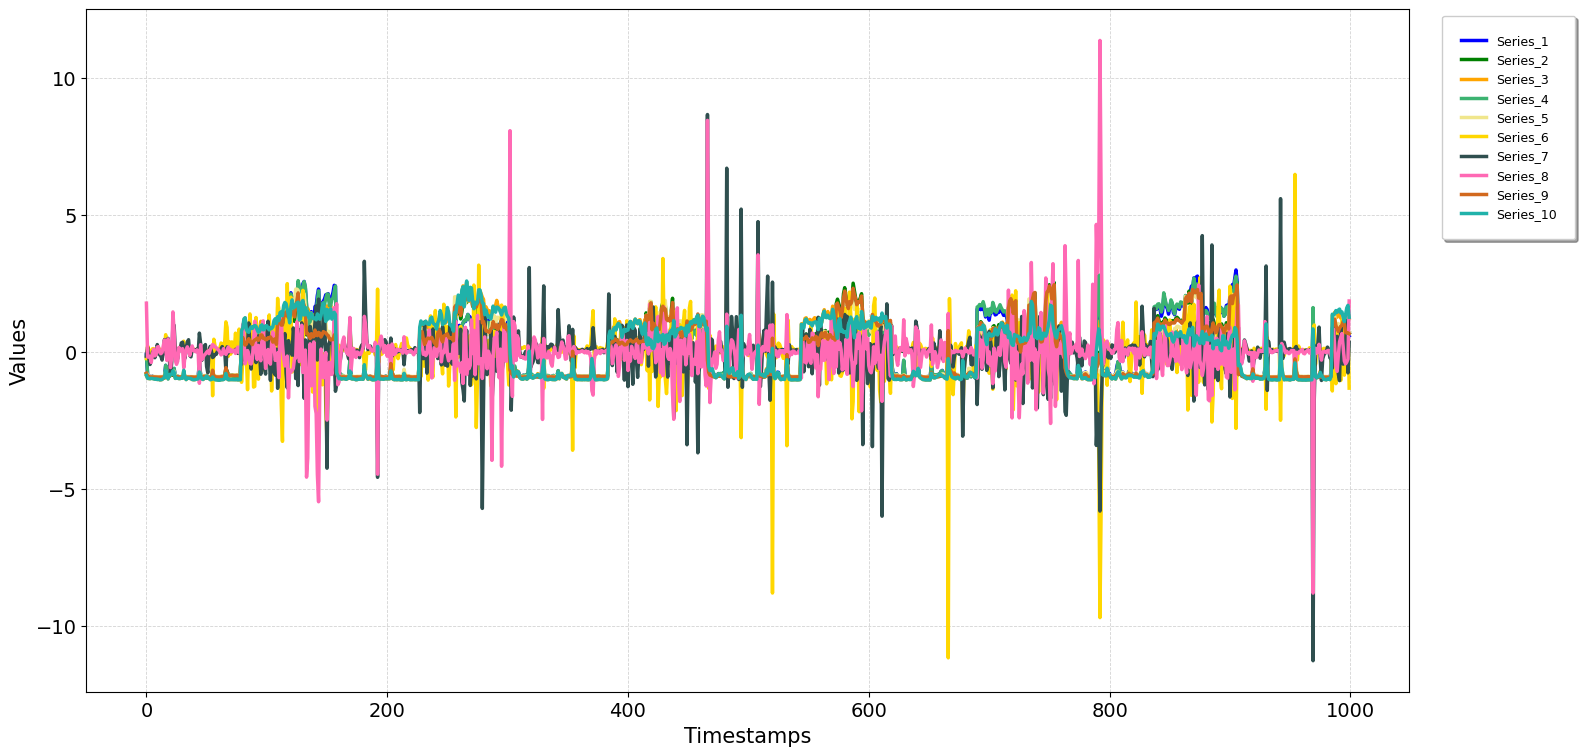

In [12]:
# load the dataset from the library
ts.load_series("airq")
ts.plot(input_data=ts.data, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

The **BAFU** dataset, kindly provided by the BundesAmt Für Umwelt (the Swiss Federal Office for the Environment), contains water discharge time series collected from different Swiss rivers containing between 200k and 1.3 million values each and covers the time period from 1974 to 2015.


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/bafu.txt

> logs: normalization (z_score) of the data - runtime: 0.0163 seconds

plots saved in: ./imputegap_assets/26_11_26_17_06_29_imputegap_plot.jpg


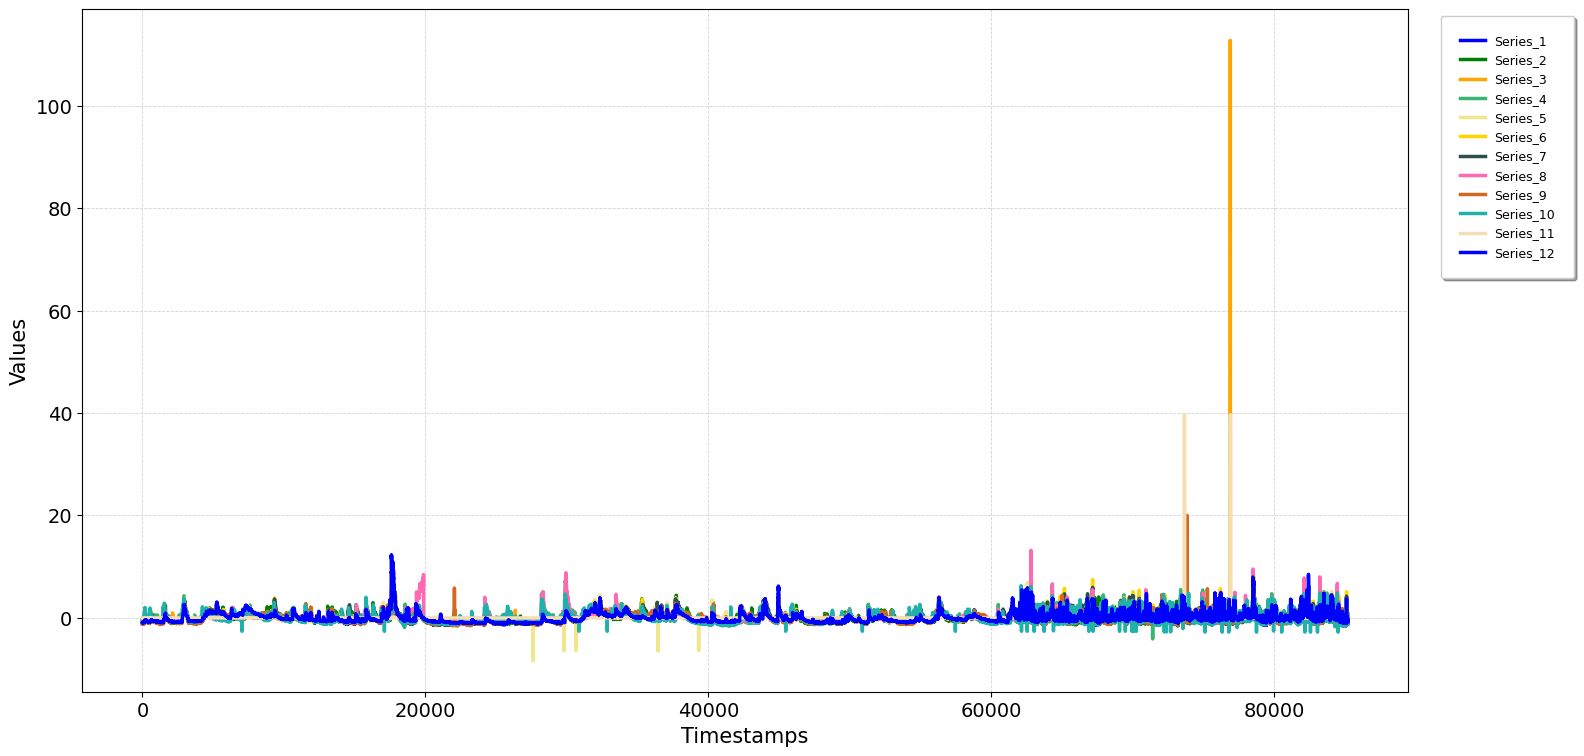

In [13]:
# load the dataset from the library
ts.load_series("bafu")
ts.plot(input_data=ts.data, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

## 2.2&nbsp;Plotting Customization

The functions `print()` or `plot()`, provided by the manager object TimesSeries, allow to display numerically or visually the different time series.

In [14]:
from imputegap.recovery.manager import TimeSeries

# initialize the time series object
ts = TimeSeries()

# load and normalize the dataset from the library
ts.load_series("bafu")

# print a subset of time series
ts.print()


ImputeGAP Library has been invoked (https://github.com/eXascaleInfolab/ImputeGAP)


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/bafu.txt

> logs: normalization (z_score) of the data - runtime: 0.0293 seconds

shape of bafu : (85203, 12)
	number of series		= 12
	number of timestamps	= 85203

                  series_0       series_1       series_2       series_3       series_4       series_5       series_6       
timestamp_1      -1.1986480799  -0.9785036738  -0.1106393112  -0.4123336415  -0.8415498034  -0.7641010673  -0.8642578888
timestamp_2      -1.2022828591  -0.9823556731  -0.1090280722  -0.4123336415  -0.8415498034  -0.7520748095  -0.8665796950
timestamp_3      -1.1986480799  -0.9785036738  -0.1080613288  -0.4188661076  -0.8388987152  -0.7580879384  -0.8689015013
timestamp_4      -1.1986480799  -0.9785036738  -0.1077390811  -0.4188661076  -0.8442008915  -0.7661054436  -0.8712233075
timestamp_5      -1.1950133007  -

The `load_series` function allows to filter the number of series and the number of values of the time series. The same functionality can be used directly at the plotting level.


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/bafu.txt

> logs: normalization (z_score) of the data - runtime: 0.0187 seconds

plots saved in: ./imputegap_assets/26_11_26_17_06_45_imputegap_plot.jpg


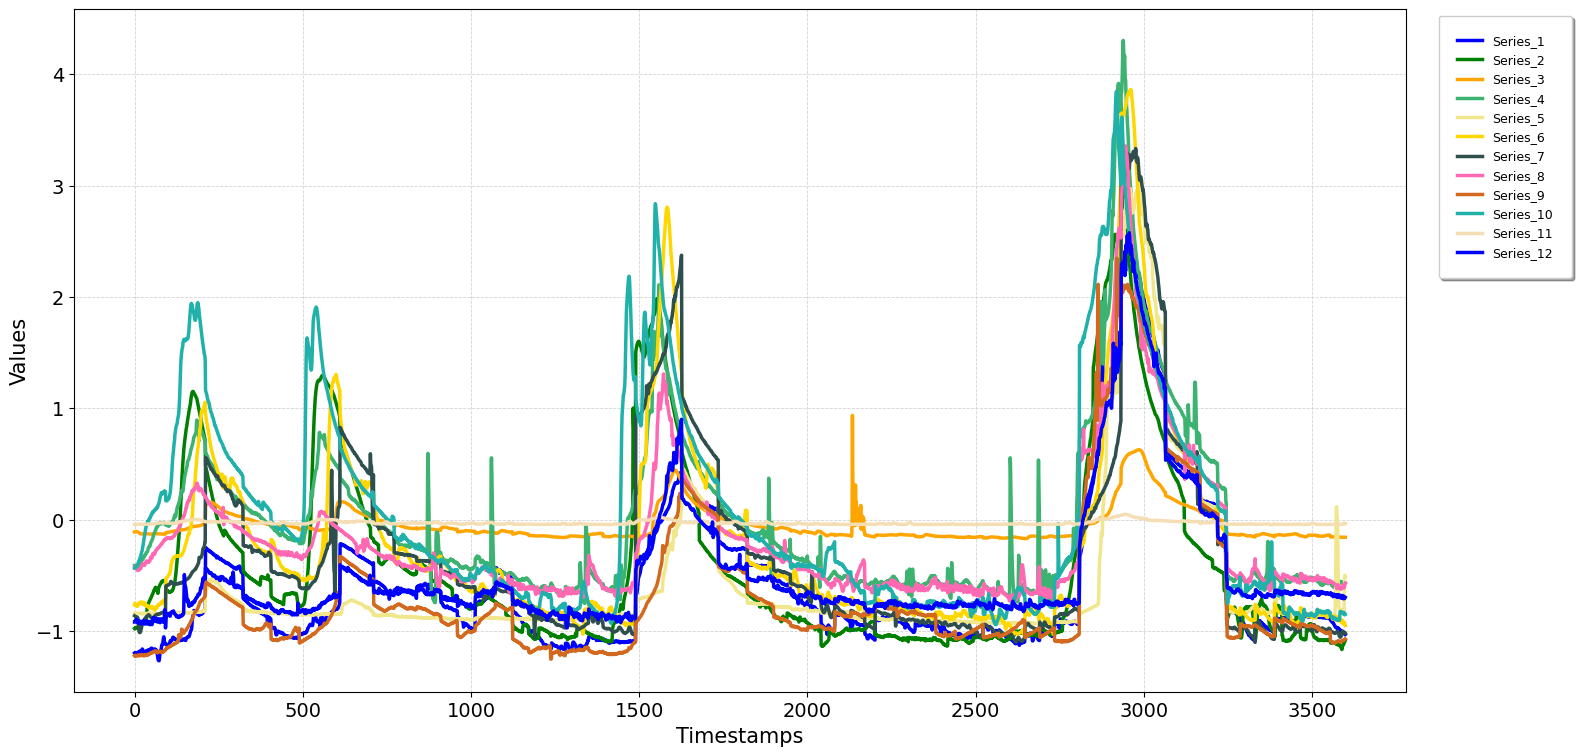

In [15]:
# load and normalize the dataset from the library
ts.load_series(utils.search_path("bafu"))
ts.plot(input_data=ts.data, nbr_val=3600, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/bafu.txt

> logs: normalization (z_score) of the data - runtime: 0.0178 seconds

plots saved in: ./imputegap_assets/26_11_26_17_06_54_imputegap_plot.jpg


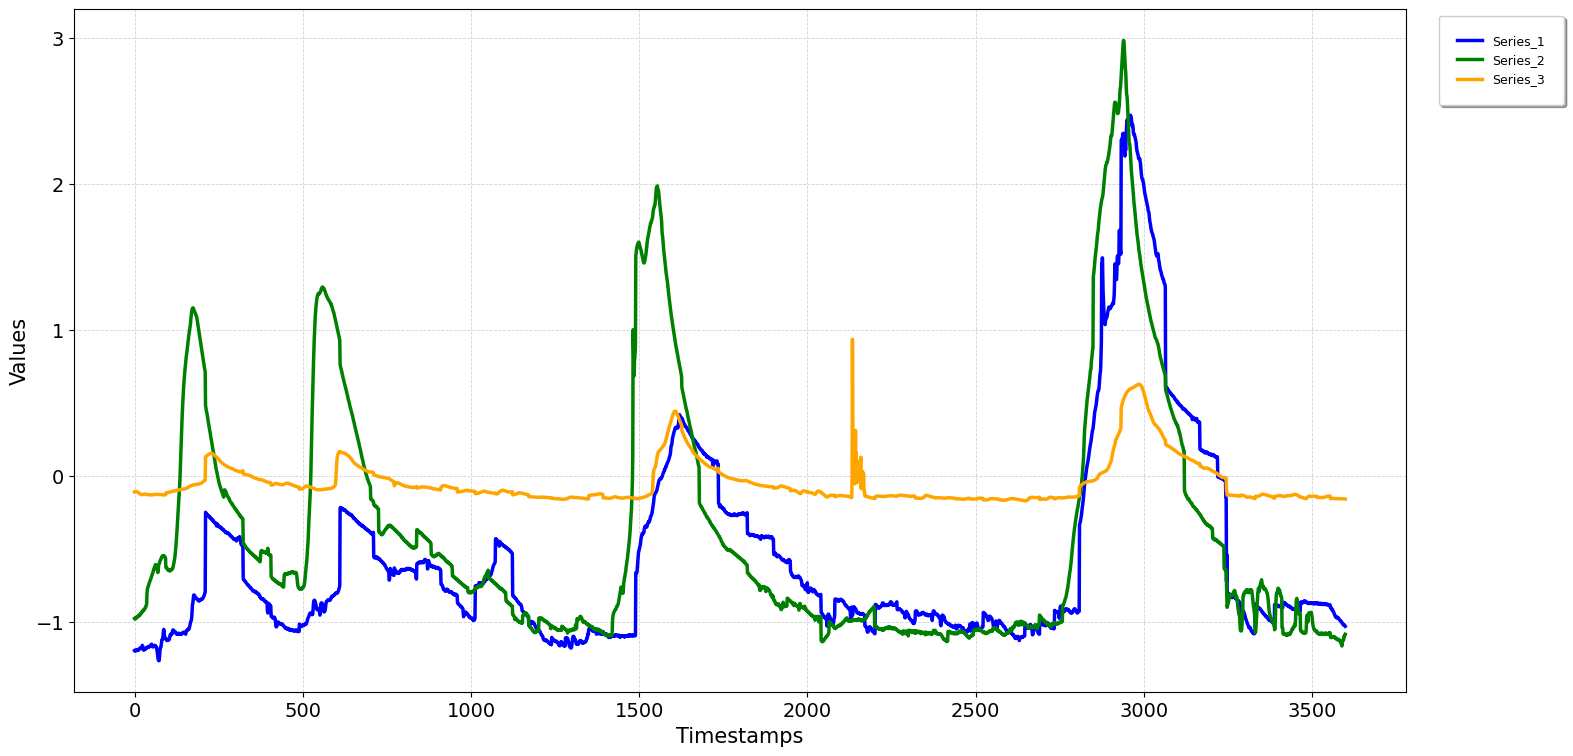

In [16]:
# load the BAFU dataset from the library
ts.load_series("bafu")
ts.plot(input_data=ts.data, nbr_series=3, nbr_val=3600, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

## 2.3&nbsp;Load as a Matrix

To import the time series as a matrix, add it to the ``ts.import_matrix`` function:

In [17]:
from imputegap.recovery.manager import TimeSeries
ts = TimeSeries()
mat = [[2,3,9], [3,10,5], [-1,4,5], [0,0,0]]
ts.import_matrix(mat)

imputegap_jupyter(ts.data)


ImputeGAP Library has been invoked (https://github.com/eXascaleInfolab/ImputeGAP)



,0,1,2
1,2,3,9
2,3,10,5
3,-1,4,5
4,0,0,0



plots saved in: ./imputegap_assets/26_11_26_17_07_01_imputegap_plot.jpg


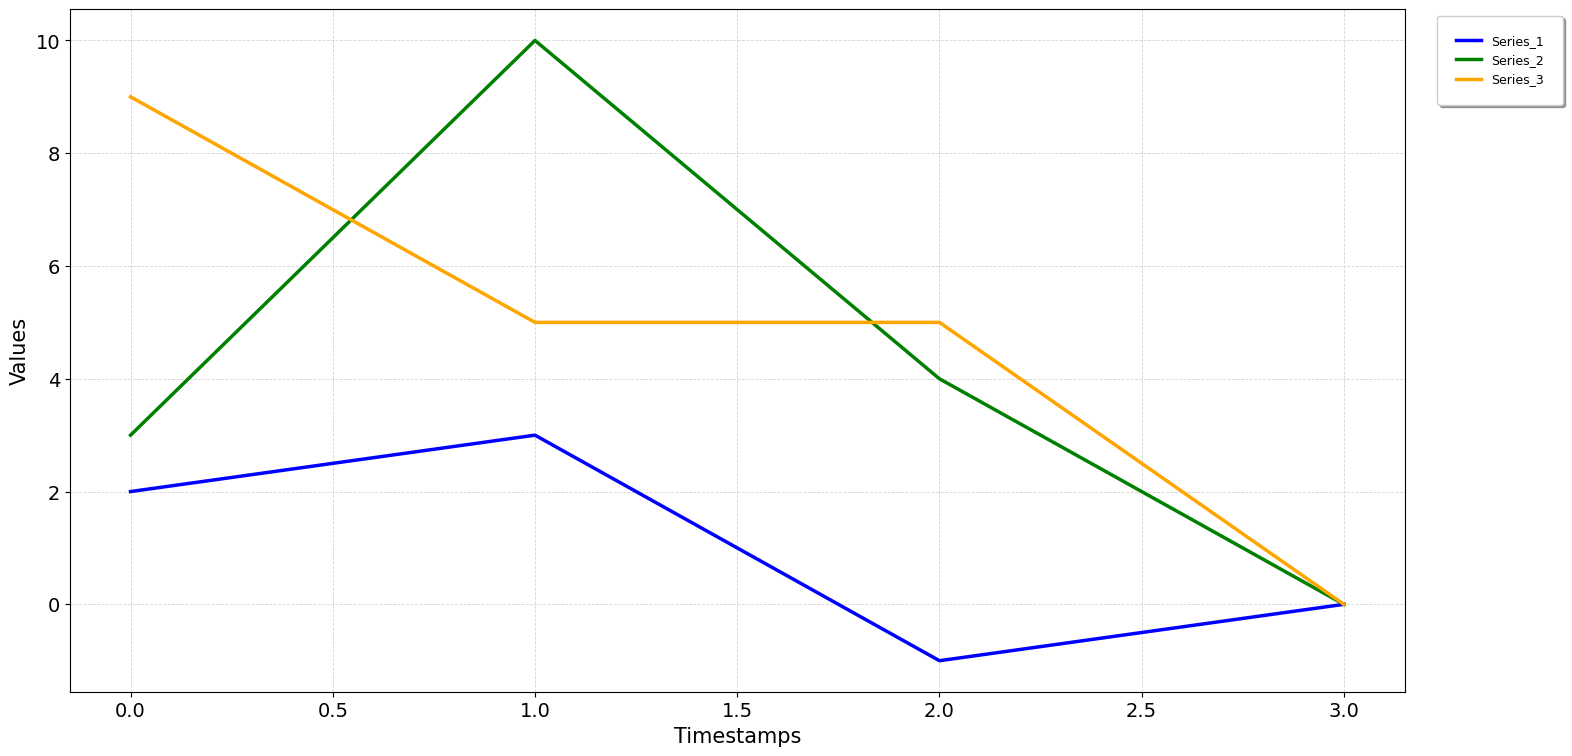

In [18]:
ts.plot(input_data=ts.data, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

## 2.4&nbsp;Load External Datasets

To load your own dataset, add the path to your file in the ``ts.load_series`` function:

In [19]:
from imputegap.recovery.manager import TimeSeries
ts = TimeSeries()
ts.load_series("test.txt")  # PATH of your dataset

imputegap_jupyter(ts.data)


ImputeGAP Library has been invoked (https://github.com/eXascaleInfolab/ImputeGAP)


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/test.txt

> logs: normalization (z_score) of the data - runtime: 0.0004 seconds


,0,1,2,3,4,5,6,7,8,9
1,-0.51,-0.26,-2.10,-1.24,-0.97,-1.06,0.41,-0.01,-0.63,-2.28
2,1.58,-0.92,1.70,1.80,1.82,1.57,1.55,-0.01,-0.63,-2.28
3,-0.51,-0.70,1.57,1.64,1.66,1.72,0.41,-0.01,-0.63,-0.24
4,1.58,-0.48,1.43,1.48,1.50,1.26,1.66,-0.01,-0.63,-0.24
5,-0.51,0.63,1.29,1.32,1.33,0.02,-0.05,-0.01,-0.63,-1.26
6,0.54,0.85,1.16,1.16,1.17,1.57,-0.05,-0.01,1.27,0.78
7,0.54,-1.36,1.02,1.00,1.00,1.72,1.09,-0.01,1.51,-1.05
8,0.54,-1.36,0.89,0.84,0.84,0.49,1.09,-0.01,1.74,0.58
9,0.54,-1.36,0.61,0.68,0.67,0.33,-0.05,3.45,1.98,-1.26
10,0.54,-1.36,0.48,0.52,0.51,1.72,0.07,-3.47,1.74,0.78



plots saved in: ./imputegap_assets/26_11_26_17_07_06_imputegap_plot.jpg


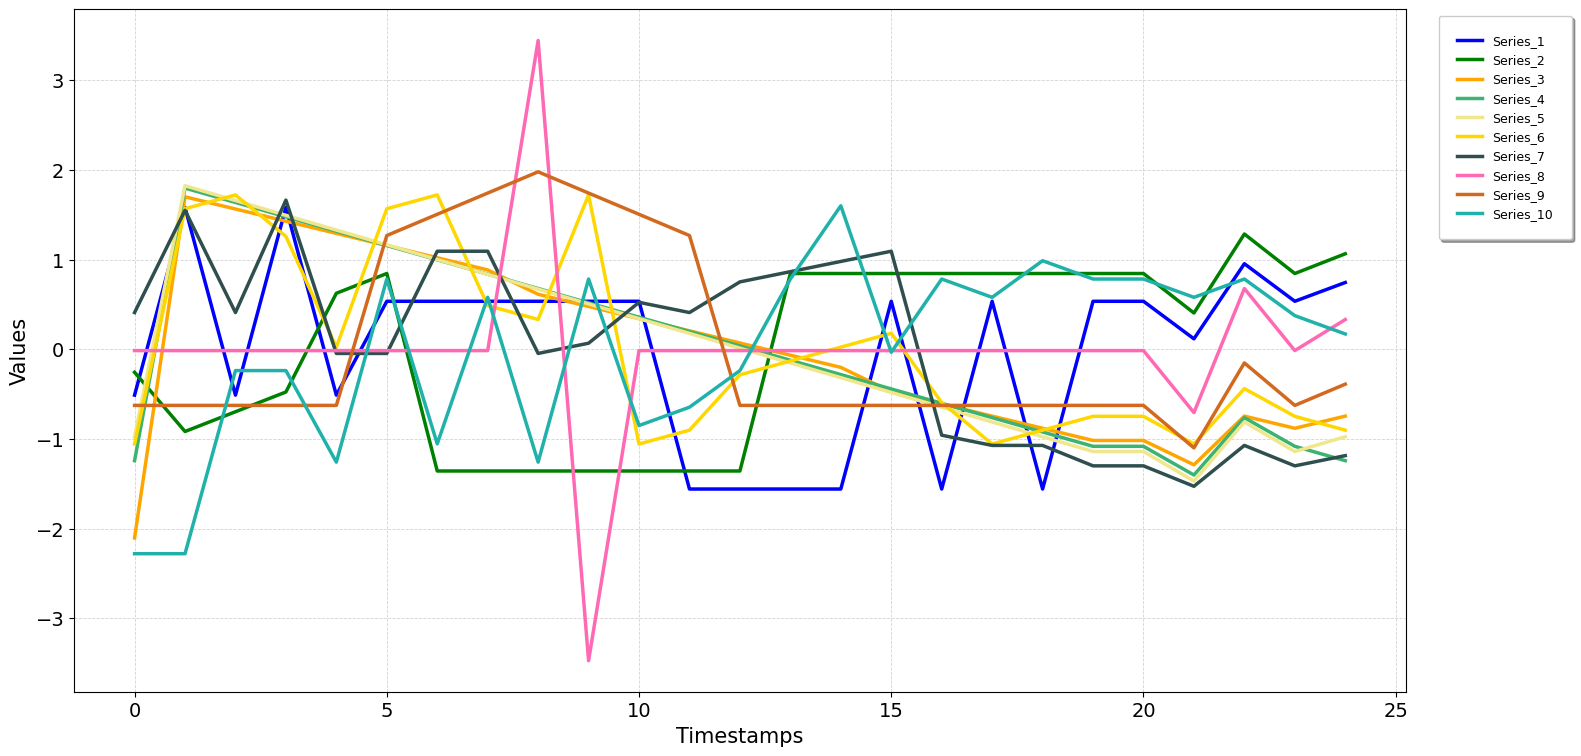

In [20]:
ts.plot(input_data=ts.data, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

## 2.5&nbsp;Data Preprocessing


The time series datasets can be normalized before being used. This step can have a drastic impact on the performance of some imputation algorithms.


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/bafu.txt

> logs: normalization (z_score) of the data - runtime: 0.0009 seconds
> logs: normalization (z_score) of the data - runtime: 0.0004 seconds

plots saved in: ./imputegap_assets/26_11_26_17_07_16_imputegap_plot.jpg


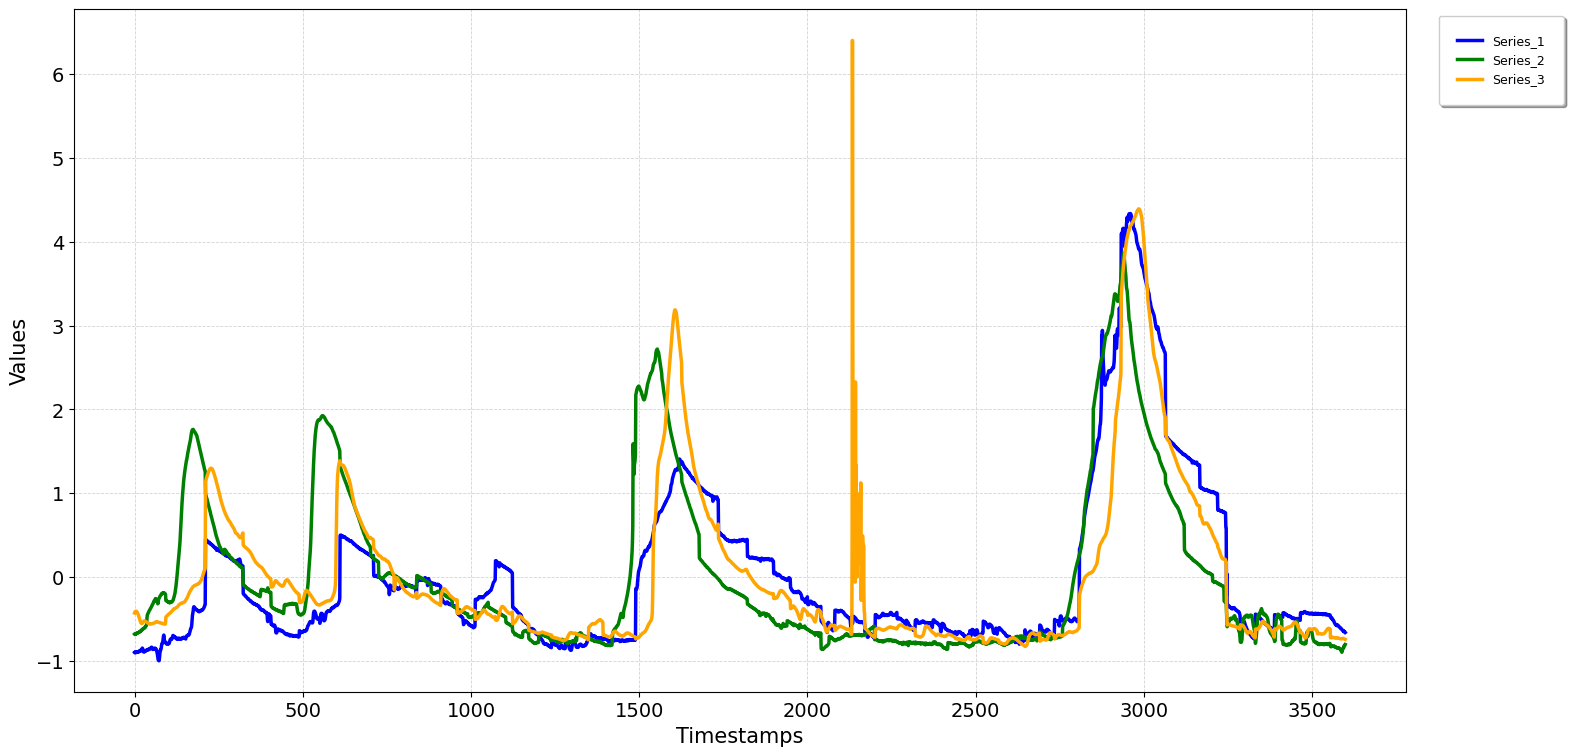

In [21]:
# load and normalize the dataset from the library
ts.load_series("bafu", nbr_series=3, nbr_val=3600)
ts.normalize(normalizer="z_score")
ts.plot(input_data=ts.data, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

Extend your normalizer to your implementation or any APIs such as sklearn


ImputeGAP Library has been invoked (https://github.com/eXascaleInfolab/ImputeGAP)


(SYS) The dataset is loaded from /mnt/c/Users/nquen/switchdrive/MST_MasterThesis/imputegap/imputegap/datasets/bafu.txt

> logs: normalization (z_score) of the data - runtime: 0.0007 seconds

plots saved in: ./imputegap_assets/26_11_26_17_07_27_imputegap_plot.jpg


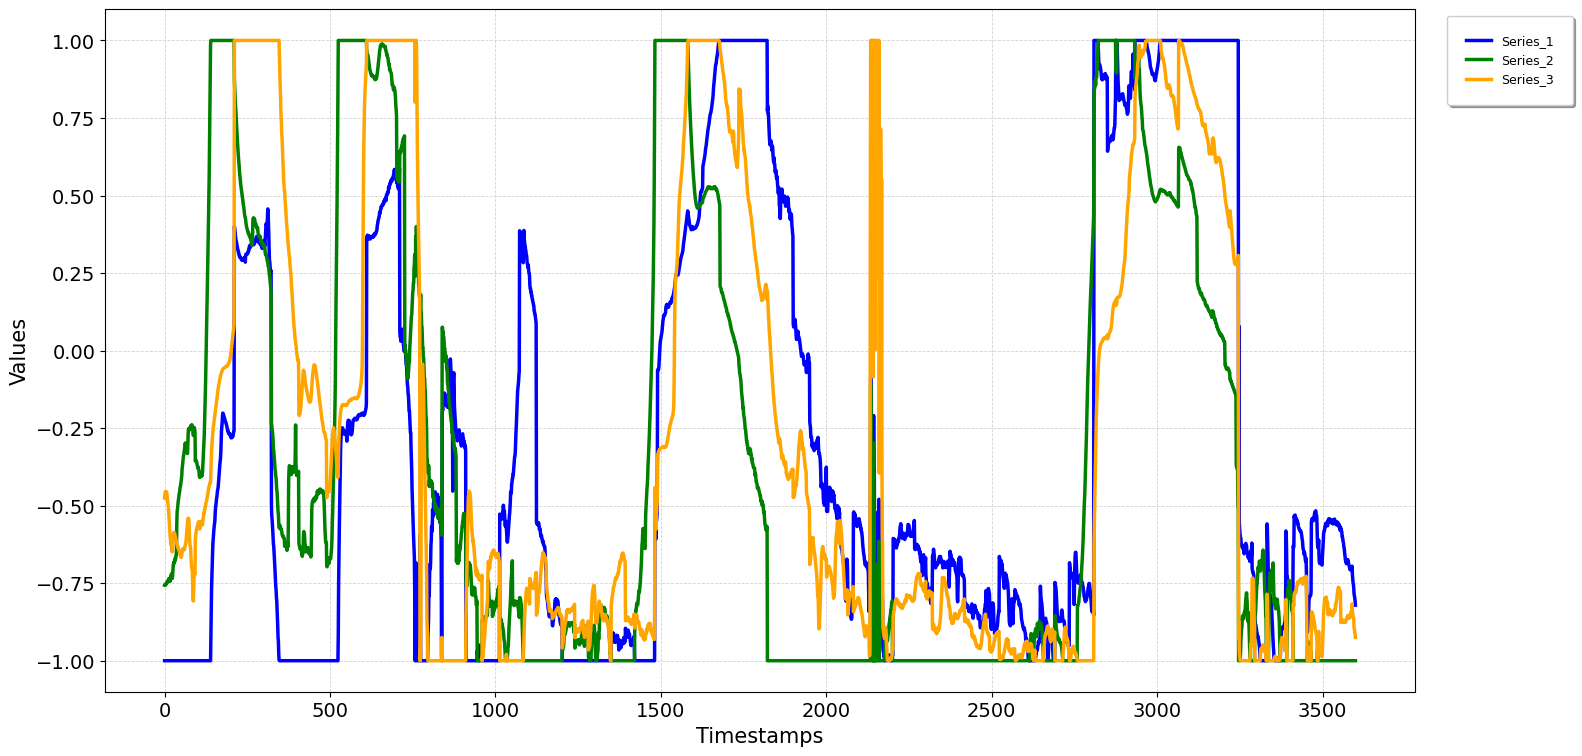

In [22]:
from sklearn.preprocessing import maxabs_scale

ts = TimeSeries()
ts.load_series("bafu", nbr_series=3, nbr_val=3600)

ts.data = maxabs_scale(ts.data, axis=1)

ts.plot(input_data=ts.data, save_path="./imputegap_assets")
%matplotlib inline
ts.plots.show()

<br>


<br>
More KDD tutorials: https://imputegap-tutorials.github.io/KDD-2025/html/materials.html